<a href="https://colab.research.google.com/github/pdtarricone/analytics_portfolio/blob/PDT_Analytics_Portfolio/K_Means_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to define a common seed value to be used throughout
RS = 0

# to suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# let colab access my google drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [10]:
# loading the dataset
customer_data = pd.read_csv('/content/drive/MyDrive/Credit_Card.csv')

In [11]:
# copying the data to another variable to avoid any changes to original data
df = customer_data.copy()

In [12]:
df.shape

(660, 7)

In [13]:
df.head(10)

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3
5,6,58634,20000,3,0,1,8
6,7,48370,100000,5,0,11,2
7,8,37376,15000,3,0,1,1
8,9,82490,5000,2,0,2,2
9,10,44770,3000,4,0,1,7


In [14]:
# fixing column names
data.columns = [c.replace(" ", "_") for c in data.columns]

In [15]:
# checking datatypes and number of non-null values for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [16]:
# checking for missing values
df.isnull().sum()

,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [17]:
# checking the number of unique values in each column
df.nunique()

,0
Sl_No,660
Customer Key,655
Avg_Credit_Limit,110
Total_Credit_Cards,10
Total_visits_bank,6
Total_visits_online,16
Total_calls_made,11


In [19]:
# fixing column names for df
df.columns = [c.replace(" ", "_") for c in df.columns]

# getting the count for each unique value in Customer_Key
data_grouped = df.groupby("Customer_Key").count()

for i in data_grouped.loc[data_grouped.Sl_No >= 2].index:
    display(df.loc[df.Customer_Key == i])

,Sl_No,Customer_Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
48,49,37252,6000,4,0,2,8
432,433,37252,59000,6,2,1,2


,Sl_No,Customer_Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
4,5,47437,100000,6,0,12,3
332,333,47437,17000,7,3,1,0


,Sl_No,Customer_Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
411,412,50706,44000,4,5,0,2
541,542,50706,60000,7,5,2,2


,Sl_No,Customer_Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
391,392,96929,13000,4,5,0,0
398,399,96929,67000,6,2,2,2


,Sl_No,Customer_Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
104,105,97935,17000,2,1,2,10
632,633,97935,187000,7,1,7,0


In [20]:
# Drop the SI_No and Customer_Key columns as they are not needed for clustering
df.drop(columns=["Sl_No", "Customer_Key"], inplace=True)

In [21]:
# Let's look at the statistical summary of the data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.0,18000.0,48000.0,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.0,5.0,6.0,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.0,2.0,4.0,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.0,2.0,4.0,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.0,3.0,5.0,10.0


In [22]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [23]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [24]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

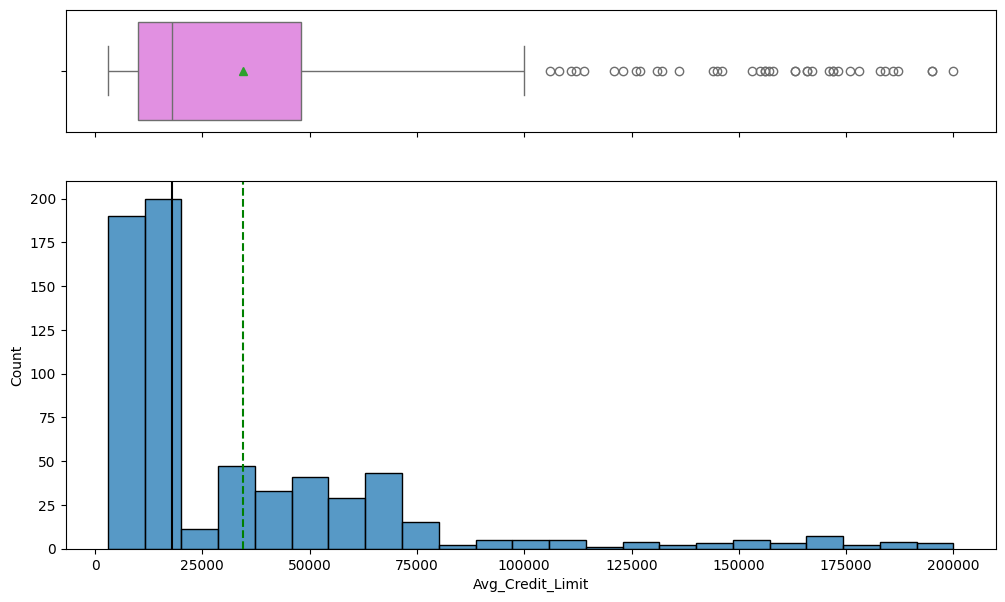

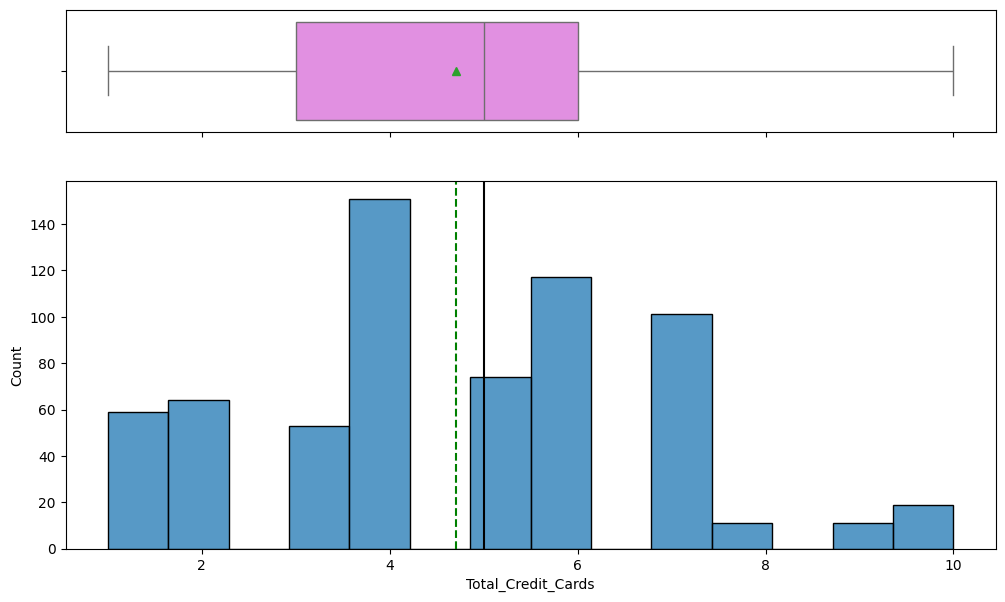

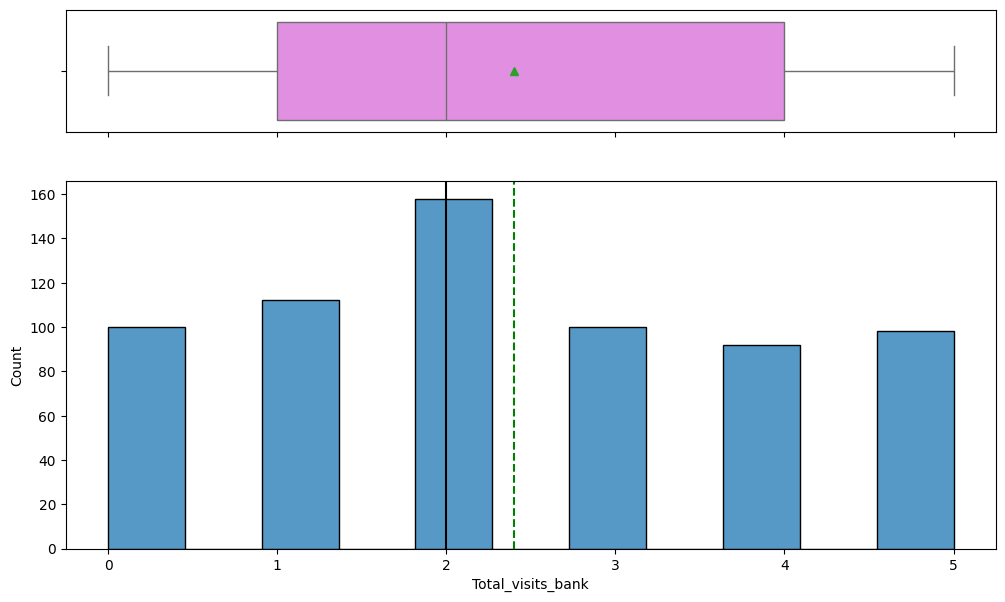

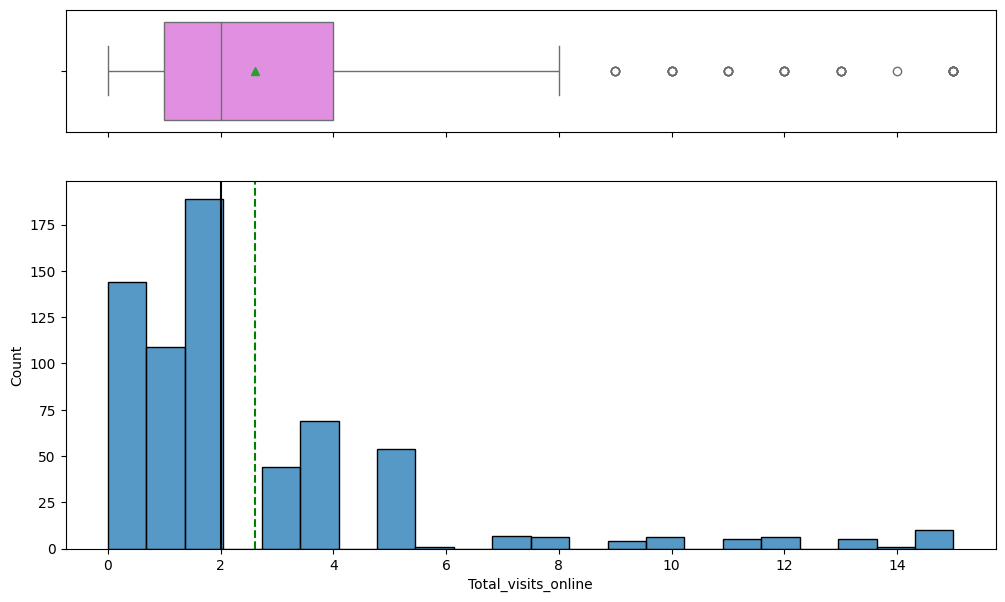

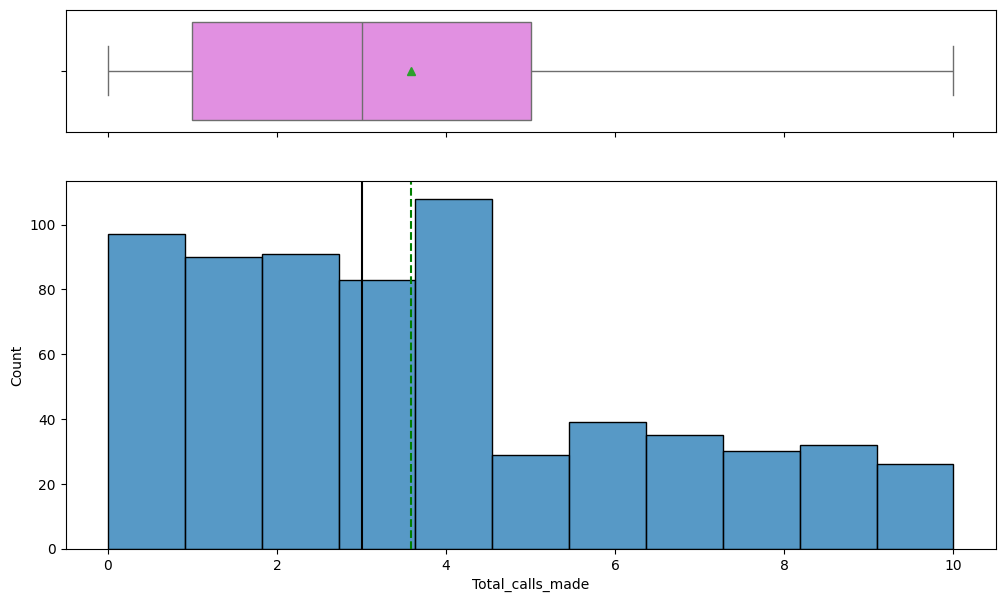

In [25]:
for col in df.columns:
    histogram_boxplot(df, col)

**Observations**

- There are outliers in the *Average_Credit_limit* column, but all the values are continuous, and the gap between the points is evenly distributed.
- In general, customers visit the bank twice a year, log in to the online portal twice a year, and make 3 calls to the customer service.
- We see some outliers in the Total_visits_online column, indicating that few customers log in to the online portal more frequently than the others.

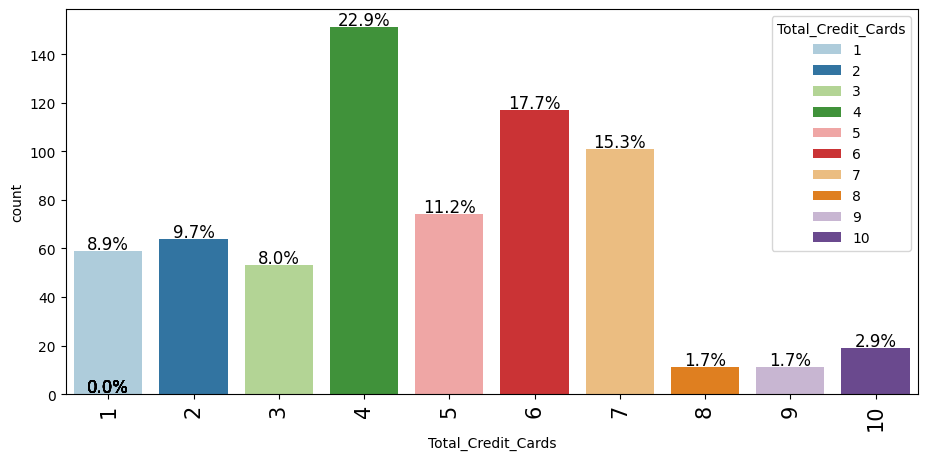

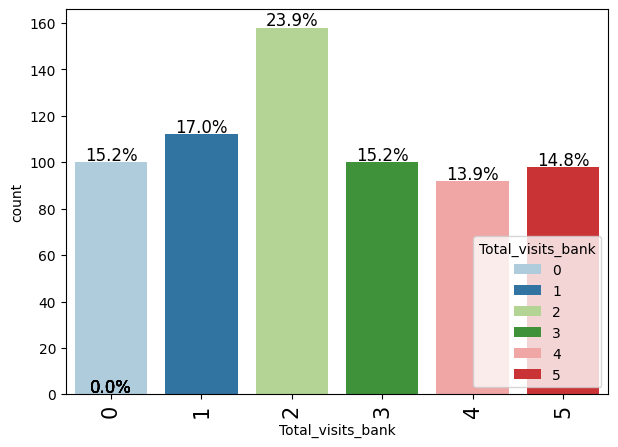

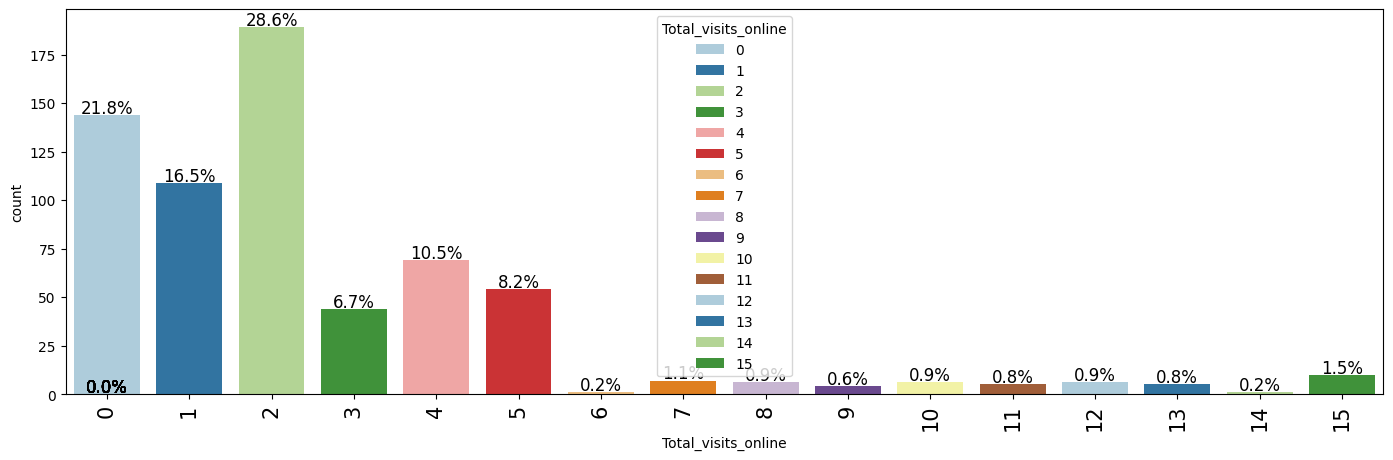

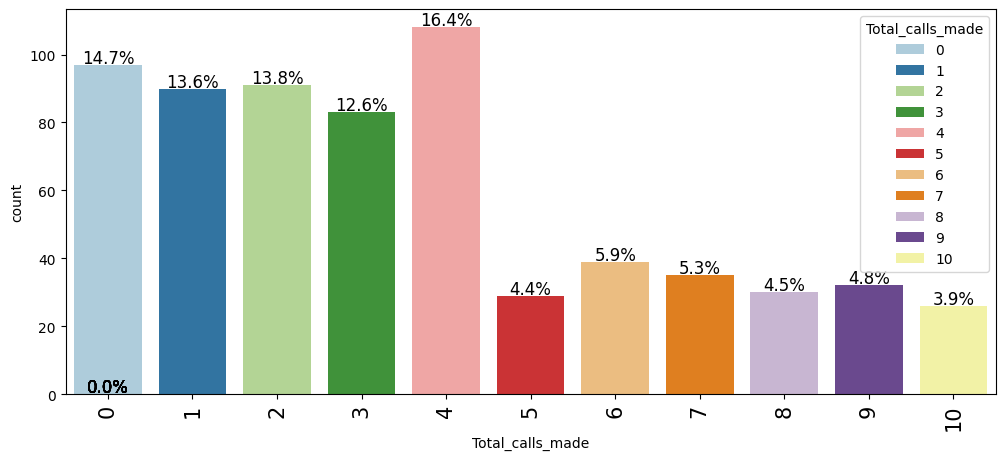

In [26]:
for col in df.columns.tolist()[1:]:
    labeled_barplot(df, col, perc=True)

**Observations**

- Approximately half the customers in the data have 4 or fewer credit cards, and very few customers (approximately 6%) have more than 7 credit cards.
- Approximately 15% of the customers have never visited the bank.
- Approximately 22% of the customers have never logged in to the online portal, while ~7% of the customers used the online banking services more than 6 or more times yearly.
- Approximately 15% of the customers have never made a service-related call to the bank.

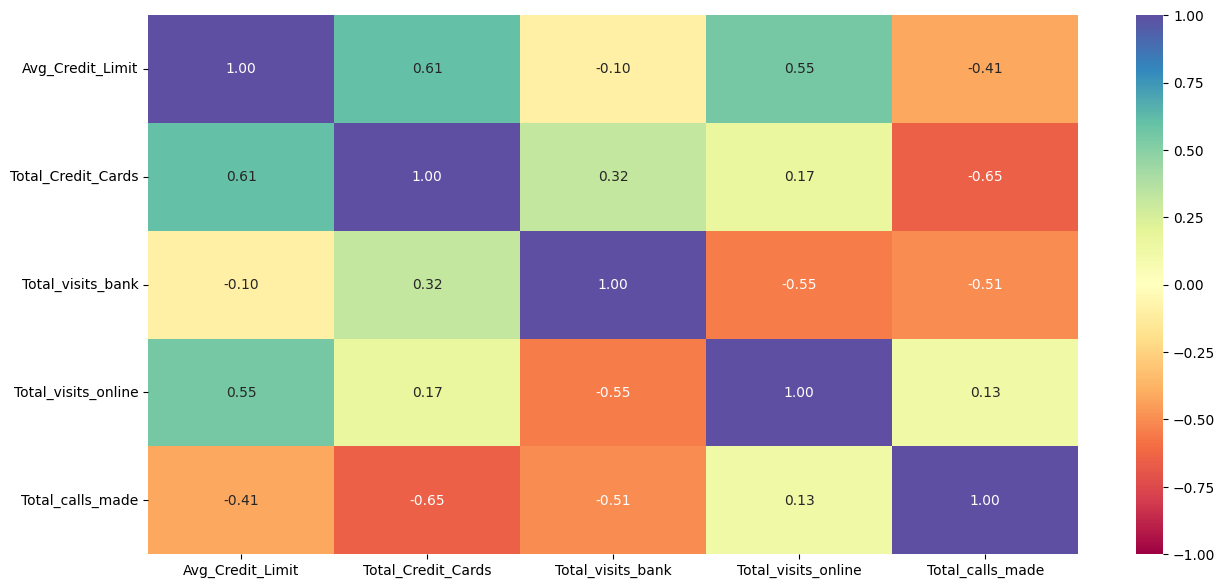

In [27]:
plt.figure(figsize=(15, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Observations**

- There is a moderate negative correlation between *Total_Calls_made* and *Total_credit_cards*.
- There is a moderate positive correlation between *Total_credit_cards* and *Avg_credit_limit*, indicating customers with a high average credit limit tend to have more credit cards.

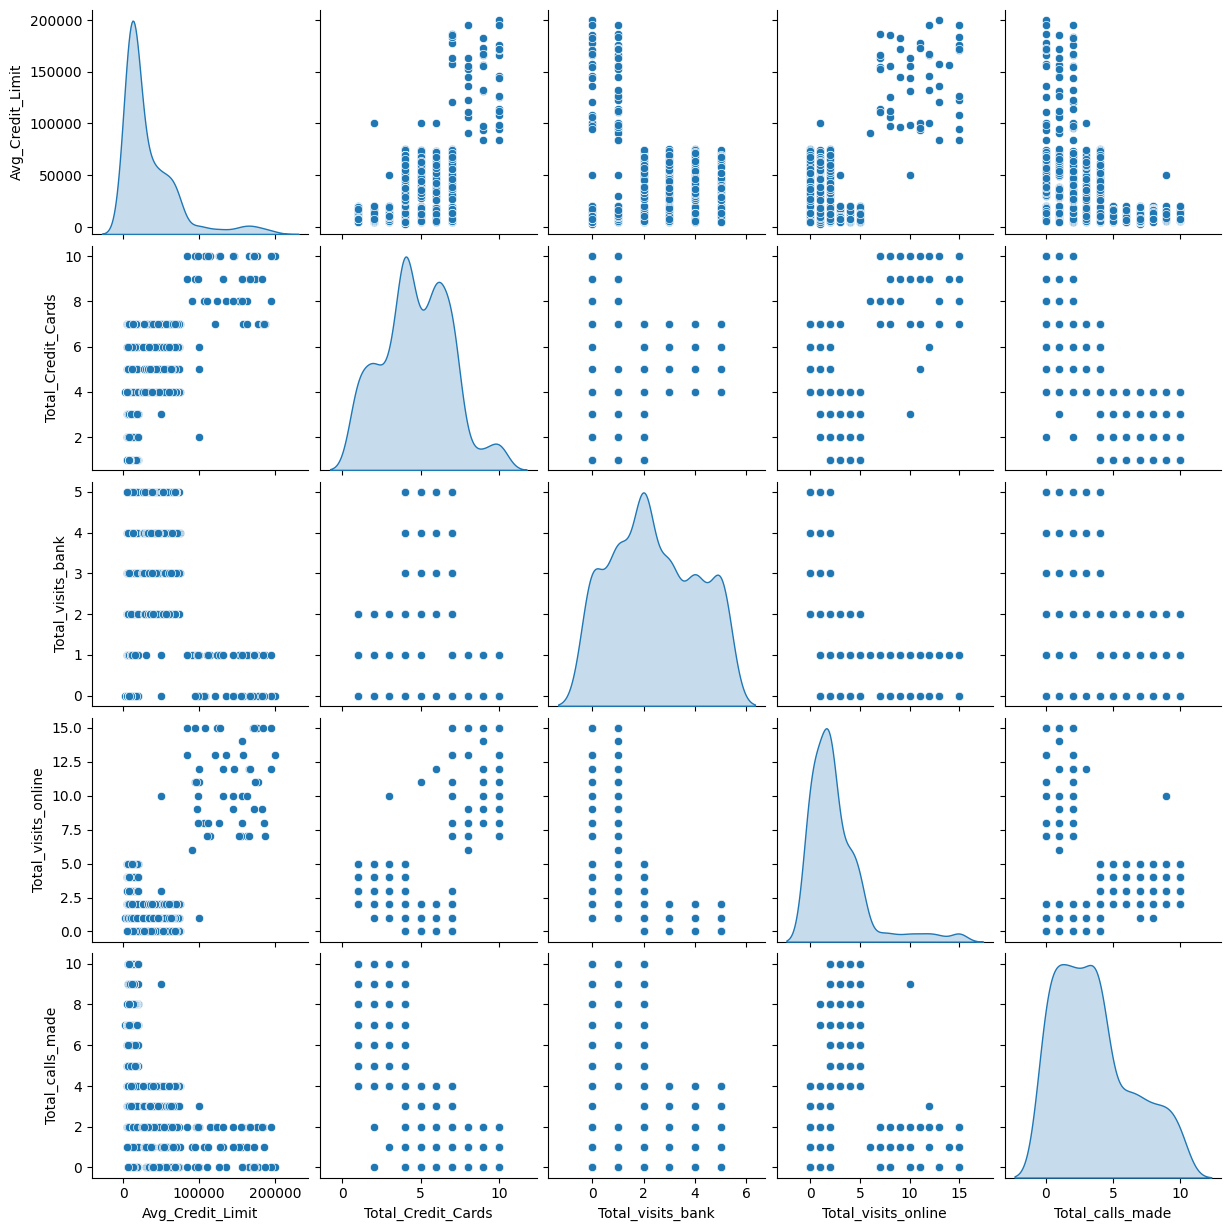

In [28]:
sns.pairplot(data=df, diag_kind="kde")
plt.show()

**Observations**

- There no clear linear correlation between the variables.
- *Total_credit_cards* may have some clusters formed w.r.t other variables.

In [29]:
# plotting a 3D scatterplot
fig = px.scatter_3d(df, x='Total_visits_bank', y='Total_visits_online', z='Total_calls_made')
fig.show()

- We can observe three segments of the customers by their preferred mode of contacting the bank.

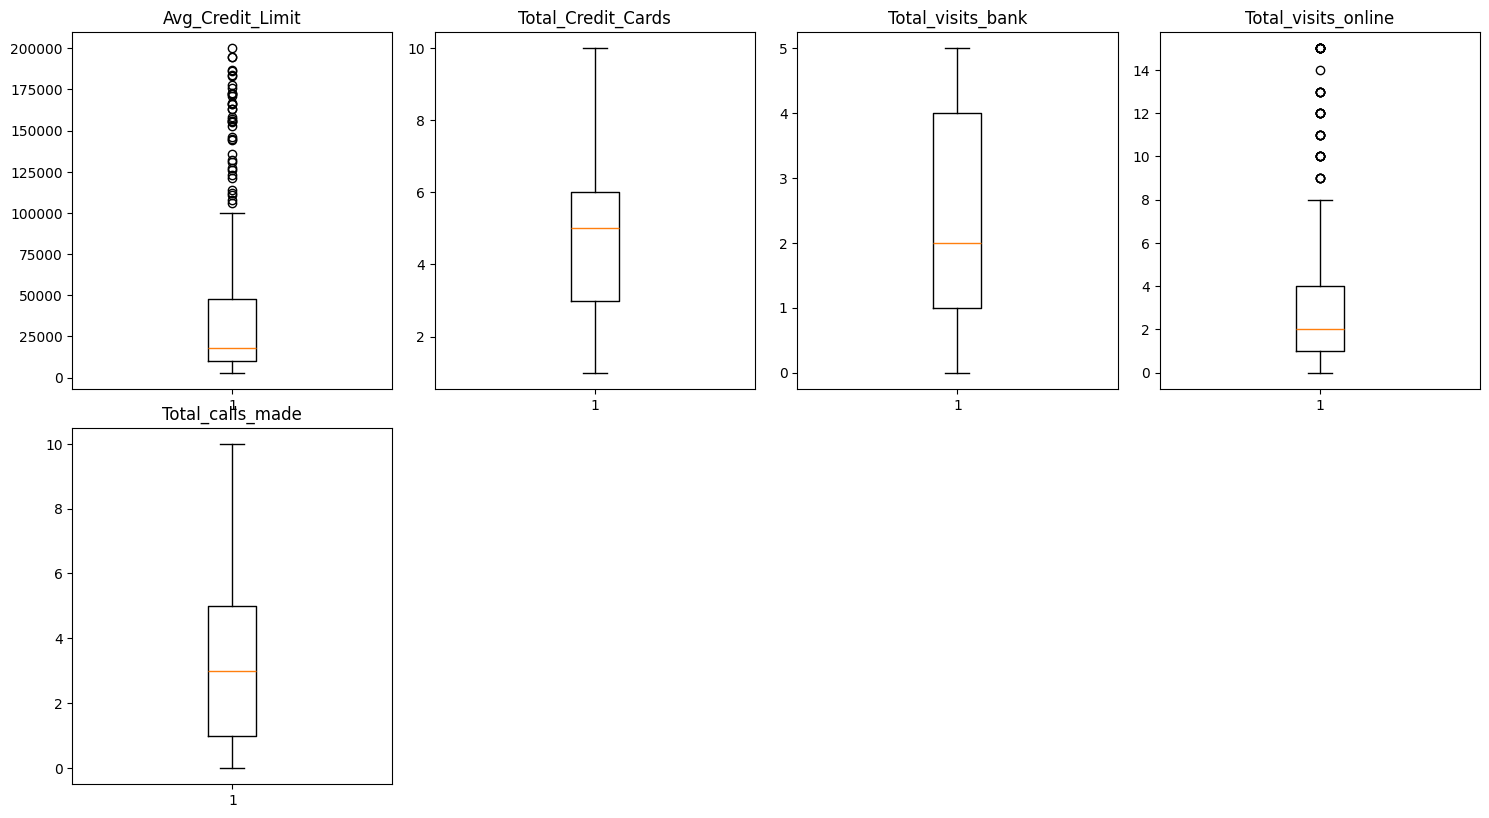

In [30]:
# outlier detection using boxplot
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(3, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

**Observations**

- There are outliers in the columns *Avg_Credit_Limit* and *Total_Visits_online*.
- We will not treat the outliers as most of those outliers are not disjoint from the curve (continues curve).
- These outliers might also form their own cluster.

In [31]:
# scaling the data before clustering
scaler = StandardScaler()
subset = df.copy()
subset_scaled = scaler.fit_transform(subset)

In [32]:
# creating a dataframe of the scaled data
subset_scaled_df = pd.DataFrame(subset_scaled, columns=subset.columns)

In [33]:
k_means_df = subset_scaled_df.copy()

In [34]:
clusters = range(2, 11)
WCSS = []

for k in clusters:
    model = KMeans(n_clusters=k, random_state=RS)
    model.fit(subset_scaled_df)
    prediction = model.predict(k_means_df)

    wcss = model.inertia_

    WCSS.append(wcss)

    print("Number of Clusters:", k, "\twcss:", wcss)

Number of Clusters: 2 	wcss: 2040.9898164784947
Number of Clusters: 3 	wcss: 933.0437490000528
Number of Clusters: 4 	wcss: 780.7736895551773
Number of Clusters: 5 	wcss: 729.7775796939327
Number of Clusters: 6 	wcss: 654.2363335547991
Number of Clusters: 7 	wcss: 621.1900732083062
Number of Clusters: 8 	wcss: 576.1657087694119
Number of Clusters: 9 	wcss: 553.8059084968586
Number of Clusters: 10 	wcss: 534.407135504733


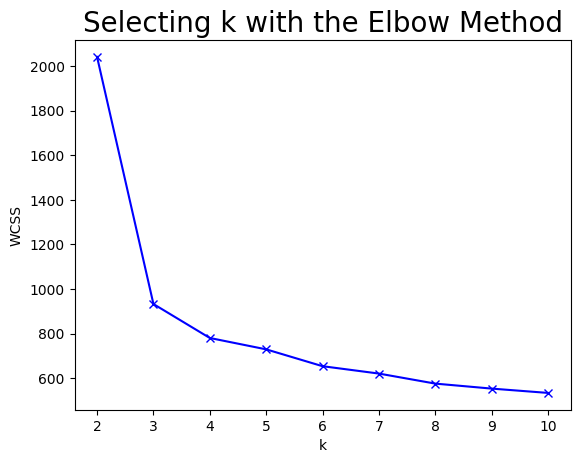

In [35]:
plt.plot(clusters,WCSS,"bx-")
plt.xlabel("k")
plt.ylabel("WCSS")
plt.title("Selecting k with the Elbow Method", fontsize=20)
plt.show()

**Observations**

- The appropriate value of k from the Elbow curve seems to be 3 or 4.

In [36]:
sil_score = []
cluster_list = range(2, 10)
for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state=RS)
    preds = clusterer.fit_predict((subset_scaled_df))
    score = silhouette_score(k_means_df, preds)
    sil_score.append(score)
    print("For n_clusters = {}, the silhouette score is {})".format(n_clusters, score))

For n_clusters = 2, the silhouette score is 0.41842496663215445)
For n_clusters = 3, the silhouette score is 0.5157182558881063)
For n_clusters = 4, the silhouette score is 0.3556670619372605)
For n_clusters = 5, the silhouette score is 0.3280708837264839)
For n_clusters = 6, the silhouette score is 0.24847126878075285)
For n_clusters = 7, the silhouette score is 0.22386857007469432)
For n_clusters = 8, the silhouette score is 0.2424290733851475)
For n_clusters = 9, the silhouette score is 0.23602958161384577)


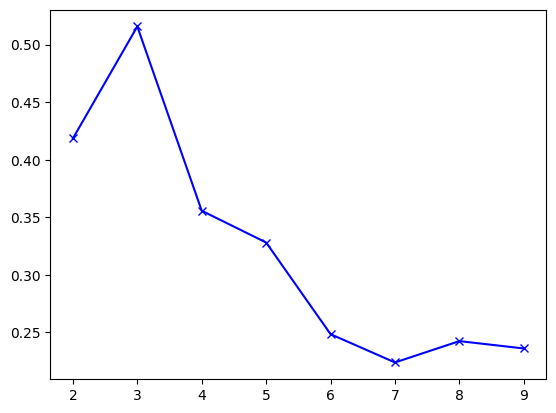

In [37]:
plt.plot(cluster_list, sil_score, "bx-")
plt.show()

**Observations**

- The silhouette coefficient for 3 clusters is the highest at approximately 0.52.
- This exceeds the 0.25 threshold stated in our objective, confirming that 3 clusters provide meaningful separation.

In [38]:
kmeans = KMeans(n_clusters=3, random_state=RS)
kmeans.fit(k_means_df)

KMeans(n_clusters=3, random_state=0)

In [39]:
# creating a copy of the original data
df1 = df.copy()

# adding kmeans cluster labels to the dataframes
k_means_df["K_means_segments"] = kmeans.labels_    # scaled
df1["K_means_segments"] = kmeans.labels_    # original

In [40]:
# 3D scatter plot of channel interaction features colored by cluster
fig = px.scatter_3d(
    df1,
    x='Total_visits_bank',
    y='Total_visits_online',
    z='Total_calls_made',
    color='K_means_segments',
    title='Customer Segments by Channel Interaction Patterns'
)
fig.show()

**Observations**

- The 3D scatter plot of channel interaction features (bank visits, online logins, calls made) colored by cluster labels shows that the segments are primarily differentiated by their preferred mode of contacting the bank.
- Cluster 0 (Branch Loyalists) dominates the high bank-visit region, Cluster 1 (Phone-First Callers) occupies the high calls-made region, and Cluster 2 (Digital Natives) clusters in the high online-visit region.
- This directly supports the business objective of tailoring service delivery by channel preference to improve CSAT from 61% to 72%.

In [41]:
km_cluster_profile = df1.groupby("K_means_segments").mean()

In [43]:
km_cluster_profile["count_in_each_segment"] = (
    df1.select_dtypes(include=np.number).groupby("K_means_segments")["Avg_Credit_Limit"].count().values
)

In [44]:
# let's display cluster profiles
km_cluster_profile.style.highlight_max(color="lightgreen", axis=0)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,count_in_each_segment
K_means_segments,,,,,,
0,33782.383420,5.515544,3.489637,0.981865,2.000000,386
1,12174.107143,2.410714,0.933036,3.553571,6.870536,224
2,141040.000000,8.740000,0.600000,10.900000,1.080000,50


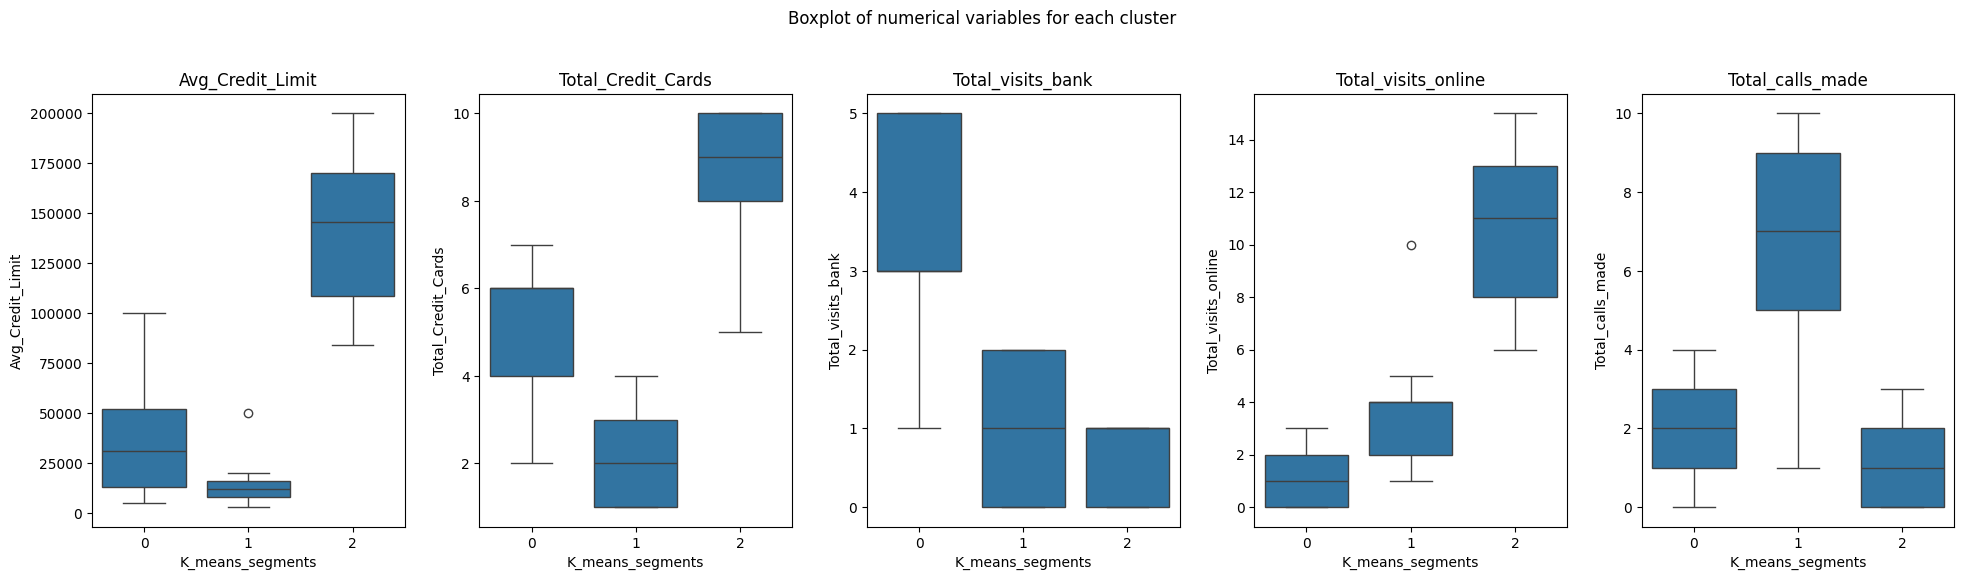

In [45]:
# Exclude the cluster label column for plotting
feature_cols = [c for c in df1.select_dtypes(include=np.number).columns if c != "K_means_segments"]

fig, axes = plt.subplots(1, len(feature_cols), figsize=(20, 6))
fig.suptitle("Boxplot of numerical variables for each cluster")
for i, col in enumerate(feature_cols):
    sns.boxplot(ax=axes[i], y=df1[col], x=df1["K_means_segments"])
    axes[i].set_title(col)

fig.tight_layout(pad=2.0)

**Cluster 0 - "Branch Loyalists" (largest segment):**

- Moderate average credit limit.
- Moderate number of total credit cards.
- Moderate to high number of visits to the bank (branch-preferred).
- Low online interactions.
- Moderate number of calls made.
- This is the largest segment, representing the bulk of the customer base.

**Cluster 1 - "Phone-First Callers" (mid-sized segment):**

- Low average credit limit.
- Low number of total credit cards.
- Low number of visits to the bank.
- Moderate online interactions.
- High number of calls made (phone-preferred).
- These customers rely heavily on phone support for their banking needs.

**Cluster 2 - "Digital Natives" (smallest segment):**

- High average credit limit.
- High number of total credit cards.
- Very low number of visits to the bank.
- Very high online interactions (digitally-preferred).
- Very low number of calls made.
- This is the smallest but highest-value segment by credit limit.

## Business Insights and Recommendations

The three clusters map directly to the two business objectives stated at the outset: (1) closing the credit card penetration gap from 34% to 45%, and (2) improving CSAT from 61% to 72% by aligning service delivery to channel preferences. Below are segment-specific recommendations for each.

---

**Cluster 0 - Branch Loyalists (largest segment, ~58% of the base)**

Penetration Strategy:
- This is the largest segment and represents the biggest volume opportunity for new card activations. Since these customers already visit branches regularly, the upsell path is clear: train relationship managers to make personalized credit card upgrade offers during in-branch interactions.
- Design branch-specific campaigns offering premium card tiers or co-branded cards, leveraging the face-to-face trust these customers already have with the bank.

CSAT Strategy:
- These customers prefer in-person interaction and show low online activity. Forcing them toward digital channels would damage satisfaction. Instead, invest in the branch experience: shorter wait times, dedicated service desks for credit card queries, and proactive outreach from branch staff.
- Consider assigning relationship managers to high-value customers in this segment to build loyalty and reduce churn risk.

---

**Cluster 1 - Phone-First Callers (~34% of the base)**

Penetration Strategy:
- This segment has low credit limits and few credit cards, suggesting they are either newer customers or underserved by current offerings. Design entry-level card products with low barriers (no annual fee, cashback on everyday spending) and promote them through the call center channel these customers already use.
- Train call center agents to identify upsell opportunities during service calls, turning inbound service interactions into acquisition moments.

CSAT Strategy:
- The high call volume in this segment suggests these customers rely on phone support for issue resolution. Invest in first-call resolution training, better call routing, and post-call satisfaction surveys for this segment.
- Gradually introduce self-service IVR options for common queries to reduce unnecessary call volume, but do not force channel migration as that would work against these customers' natural preference.

---

**Cluster 2 - Digital Natives (~8% of the base)**

Penetration Strategy:
- This is the smallest but highest-value segment with the largest credit limits and most credit cards. They are already deeply engaged digitally. Upsell premium card products (travel rewards, luxury perks) through personalized in-app offers and email campaigns.
- This segment is most at risk of being poached by digitally native competitors. Proactive engagement (credit limit increases, exclusive digital-only offers) is essential to retention.

CSAT Strategy:
- These customers almost never visit branches or call the bank, interacting almost entirely online. Their satisfaction is driven by the quality of the digital experience: app stability, intuitive self-service, and fast digital resolution of issues.
- Expand digital service channels to include in-app chat, WhatsApp, and Telegram support. Consider a dedicated digital concierge for high-value customers in this segment.